# 00 — Exploração dos dados negócio a negócio: WDO e WIN

**Objetivo:** antes de aplicar qualquer método do curso, entender os dados. As perguntas são:
- o que é um negócio;
- como o volume se distribui ao longo do dia;
- como são os retornos (caudas, autocorrelação);
- se o fluxo de agressão tem alguma relação com o preço no minuto seguinte.

Conceitos do curso usados aqui: **Cap. 2** ($Y = f(X) + \varepsilon$, predição × inferência) e uma prévia do **Cap. 3** (regressão linear).

**Pré-requisitos:**
```
python -m src.b3_download --dias 30   # baixa os .zip para data/raw/
python -m src.pipeline                # processa um pregão por vez para data/processed/
```

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from statsmodels.graphics.tsaplots import plot_acf

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
from src.pipeline import build, load
from src.features import add_forward_return

plt.rcParams["figure.figsize"] = (11, 4)
build()  # processa só os pregões novos de data/raw/

[]

## 1. Visão geral dos pregões
Cada pregão traz vários vencimentos. O pipeline fica só com o de maior volume (vencimento principal).

In [2]:
summary = load("summary").reset_index()
summary["root"] = summary["ticker"].str[:3]
por_dia = summary.pivot_table(index="day", columns="root", values=["negocios", "contratos"], aggfunc="sum")
print(f"{len(por_dia)} pregões: {por_dia.index.min()} a {por_dia.index.max()}")
por_dia.describe().loc[["mean", "min", "max"]].round(0)

20 pregões: 2026-10-20 a 2026-11-17


contratos               negocios           
root        WDO         WIN        WDO        WIN
mean  3090847.0  20225695.0   708189.0  6598529.0
min   1996720.0  12447691.0   444450.0  5001984.0
max   4700076.0  25371652.0  1097163.0  9345592.0

In [3]:
raw = load("bars_1min")
bars = {r: add_forward_return(g.drop(columns="root"), 1) for r, g in raw.groupby("root")}
bars["WDO"].head()

,open,high,low,close,volume,n_trades,signed_volume,vwap,imbalance,ret,fwd_ret_1
ts,,,,,,,,,,,
2026-10-20 09:00:00,5055.0,5056.5,5051.5,5053.5,6926,1601,-972,5054.289344,-0.140341,NaN,-0.003072
2026-10-20 09:01:00,5053.0,5053.5,5037.0,5038.0,26662,6738,-9196,5044.729334,-0.344910,-0.003072,0.000298
2026-10-20 09:02:00,5038.0,5041.0,5036.5,5039.5,16036,4595,506,5038.019799,0.031554,0.000298,0.000298
2026-10-20 09:03:00,5039.5,5042.0,5038.0,5041.0,9841,2828,2341,5040.124835,0.237882,0.000298,-0.000794
2026-10-20 09:04:00,5040.5,5041.5,5036.0,5037.0,11933,2835,-2101,5038.434719,-0.176066,-0.000794,-0.000993


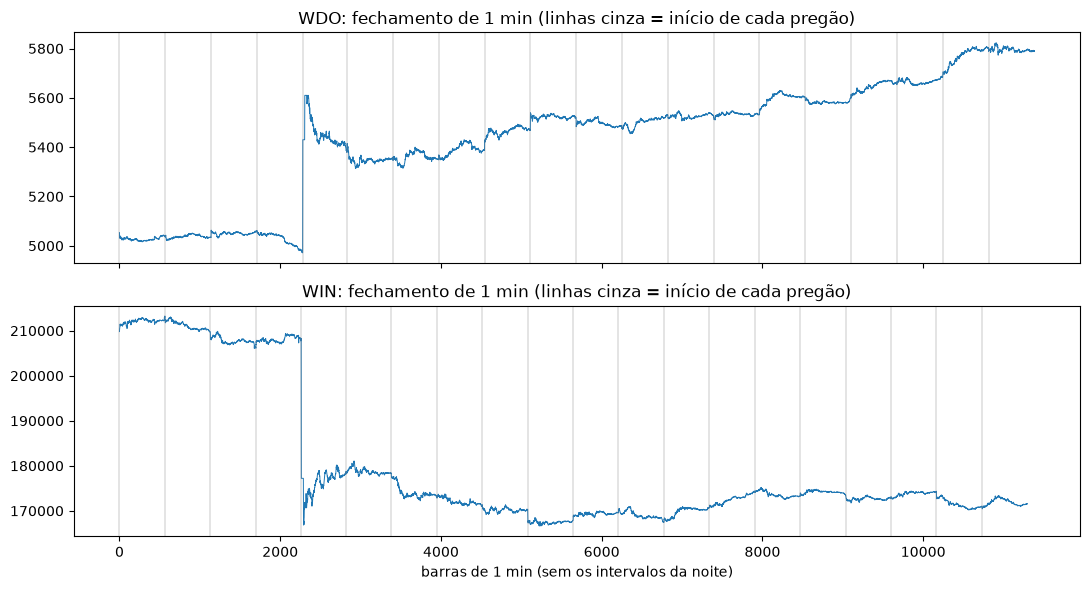

In [4]:
fig, axes = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
for ax, (root, b) in zip(axes, bars.items()):
    ax.plot(range(len(b)), b["close"].values, lw=0.7)
    starts = np.flatnonzero(b.index.normalize().to_series().diff().ne(pd.Timedelta(0)))
    for s in starts:
        ax.axvline(s, color="grey", lw=0.3)
    ax.set_title(f"{root}: fechamento de 1 min (linhas cinza = início de cada pregão)")
axes[-1].set_xlabel("barras de 1 min (sem os intervalos da noite)")
plt.tight_layout()

## 2. Perfil intradiário do volume
A hipótese é um formato de "U", com mais volume na abertura e no fechamento.

Text(0.5, 1.0, 'Volume mediano por minuto do dia')

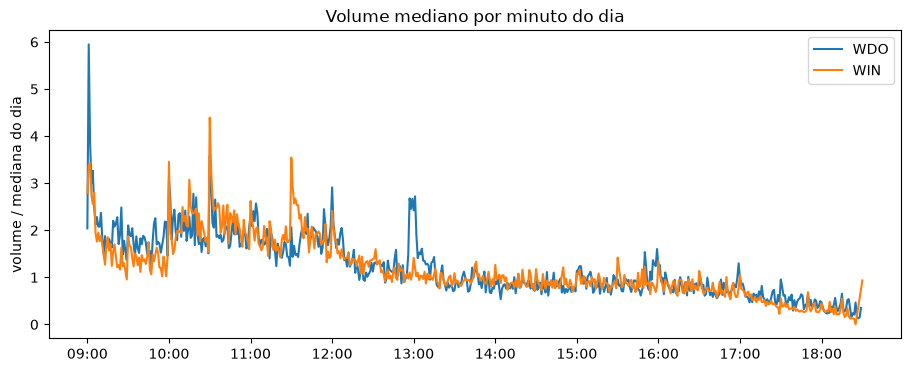

In [5]:
fig, ax = plt.subplots()
for root, b in bars.items():
    prof = b.groupby(b.index.strftime("%H:%M"))["volume"].median()
    ax.plot(prof.index, prof / prof.median(), label=root)
ax.set_xticks(ax.get_xticks()[::60]); ax.set_ylabel("volume / mediana do dia"); ax.legend()
ax.set_title("Volume mediano por minuto do dia")

## 3. Distribuição dos retornos de 1 minuto
Retornos financeiros costumam ter **caudas gordas**, ou seja, curtose bem acima de 3 (o valor da normal).

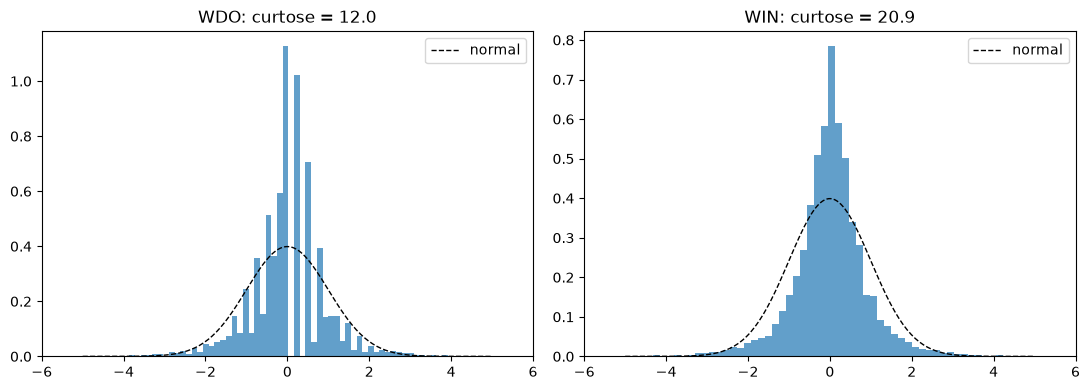

In [6]:
fig, axes = plt.subplots(1, 2)
for ax, (root, b) in zip(axes, bars.items()):
    r = b["ret"].dropna()
    ax.hist(r / r.std(), bins=150, density=True, alpha=0.7)
    x = np.linspace(-5, 5, 200); ax.plot(x, np.exp(-x**2 / 2) / np.sqrt(2 * np.pi), "k--", lw=1, label="normal")
    ax.set_xlim(-6, 6); ax.set_title(f"{root}: curtose = {r.kurt() + 3:.1f}"); ax.legend()
plt.tight_layout()

## 4. Autocorrelação
Uma autocorrelação negativa no lag 1 costuma vir do *bid-ask bounce*: o preço alterna entre negócios no bid e no ask.

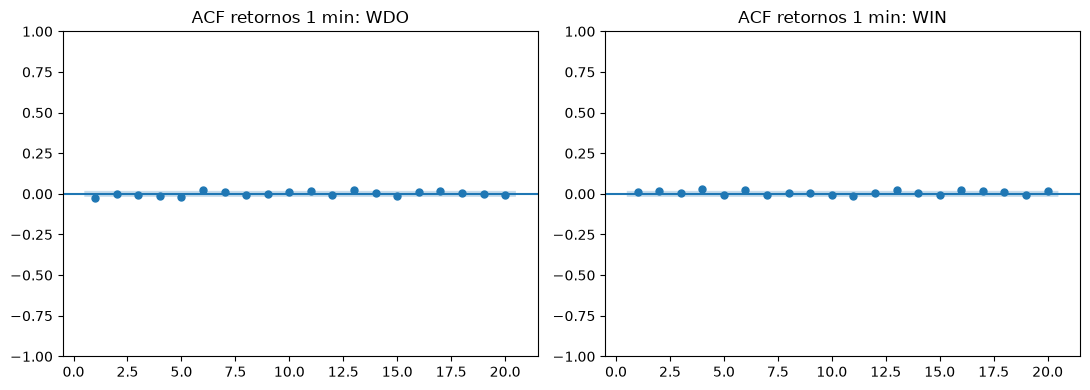

In [7]:
fig, axes = plt.subplots(1, 2)
for ax, (root, b) in zip(axes, bars.items()):
    plot_acf(b["ret"].dropna(), lags=20, ax=ax, title=f"ACF retornos 1 min: {root}", zero=False)
plt.tight_layout()

## 5. Fluxo de agressão → retorno seguinte (prévia do Cap. 3)
`imbalance` = (volume comprador − vendedor) / volume. O lado de cada negócio é estimado pela *tick rule*, porque o arquivo público não informa o agressor.

A correlação **no mesmo minuto** é quase mecânica: a tick rule usa o próprio preço. Para predição, o que interessa é o **minuto seguinte** (`fwd_ret_1`).
Os erros-padrão são HAC (Newey-West), robustos à autocorrelação e à heterocedasticidade que os retornos têm.

In [8]:
rows = []
for root, b in bars.items():
    d = b[["imbalance", "ret", "fwd_ret_1"]].dropna() * [1, 1e4, 1e4]  # retornos em bps
    same = smf.ols("ret ~ imbalance", d).fit(cov_type="HAC", cov_kwds={"maxlags": 5})
    nxt = smf.ols("fwd_ret_1 ~ imbalance", d).fit(cov_type="HAC", cov_kwds={"maxlags": 5})
    rows.append({"ativo": root, "n": len(d),
                 "mesmo min: beta (bps)": same.params["imbalance"], "mesmo min: t": same.tvalues["imbalance"], "mesmo min: R2": same.rsquared,
                 "próx. min: beta (bps)": nxt.params["imbalance"], "próx. min: t": nxt.tvalues["imbalance"], "próx. min: R2": nxt.rsquared})
pd.DataFrame(rows).set_index("ativo").round(4)

,n,mesmo min: beta (bps),mesmo min: t,mesmo min: R2,próx. min: beta (bps),próx. min: t,próx. min: R2
ativo,,,,,,,
WDO,11341,5.0165,44.3659,0.2458,-0.0113,-0.1431,0.0000
WIN,11235,23.0253,52.4932,0.3888,-0.4139,-1.5331,0.0001


## 6. WDO × WIN
Dólar e bolsa costumam andar em sentidos opostos: na fuga de risco, o dólar sobe e o índice cai. A pergunta é se essa relação se mantém estável de um dia para o outro.

corr(ret WDO, ret WIN) em 1 min, período todo = -0.461


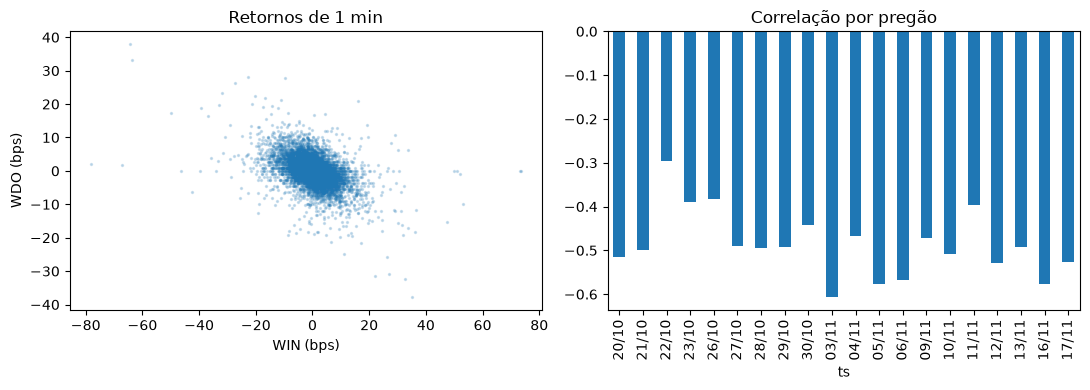

In [9]:
both = pd.concat({k: v["ret"] for k, v in bars.items()}, axis=1).dropna()
print(f"corr(ret WDO, ret WIN) em 1 min, período todo = {both.corr().iloc[0, 1]:+.3f}")
por_dia_corr = both.groupby(both.index.normalize()).apply(lambda g: g["WDO"].corr(g["WIN"]))
fig, axes = plt.subplots(1, 2)
axes[0].scatter(both["WIN"] * 1e4, both["WDO"] * 1e4, s=2, alpha=0.2); axes[0].set_xlabel("WIN (bps)"); axes[0].set_ylabel("WDO (bps)")
axes[0].set_title("Retornos de 1 min")
por_dia_corr.plot.bar(ax=axes[1], title="Correlação por pregão"); axes[1].set_xticklabels([d.strftime("%d/%m") for d in por_dia_corr.index])
plt.tight_layout()

## Conclusões e próximos passos
*(preencher)*

- …
- Próximo: `ch03_regressao_linear.ipynb`, com a regressão de `fwd_ret` em `imbalance`, retornos defasados, volume e o retorno do outro ativo, usando os diagnósticos do Cap. 3.